## 1. Задание

In [81]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets.mnist import read_image_file, read_label_file

In [82]:
class FashionMNISTDataset(Dataset):
    def __init__(self, file_dir, train=True, transform=None, target_transform=None):
        self.transform = transform
        self.target_transform = target_transform
        self.train = train
        image_file = f"{'train' if self.train else 't10k'}-images-idx3-ubyte"
        self.data = read_image_file(os.path.join(file_dir, image_file))
        label_file = f"{'train' if self.train else 't10k'}-labels-idx1-ubyte"
        self.targets = read_label_file(os.path.join(file_dir, label_file))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        image = self.data[idx]
        label = self.targets[idx]
        image = image.unsqueeze(0).float() / 255.0
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

In [83]:
train_data = FashionMNISTDataset(
    file_dir="C:\\spbu_dl_2026\\notebooks\\data\\FashionMNIST\\raw",
    train=True,
)
test_data = FashionMNISTDataset(
    file_dir="C:\\spbu_dl_2026\\notebooks\\data\\FashionMNIST\\raw",
    train=False,
)

train_dataloader = DataLoader(train_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

In [84]:
class MyFlatten(nn.Module):
    def forward(self, x):
        return x.view(x.size(0), -1)

In [85]:
class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10,
                 hidden_sizes=[512, 256, 256, 128]):
        super().__init__()
        layers = []
        layer_sizes = [input_size] + hidden_sizes
        for i in range(1, len(layer_sizes)):
            layers += [
                nn.Linear(layer_sizes[i-1], layer_sizes[i]),
                act_fn,
            ]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)
        self.config = {
            "act_fn": act_fn.__class__.__name__,
            "input_size": input_size,
            "num_classes": num_classes,
            "hidden_sizes": hidden_sizes,
        }

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for l in self.layers:
            x = l(x)
        return x

In [86]:
torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device}")

Using cpu


In [87]:
def init_weights(model,init_type,act_name):
    for m in model.modules():
        if isinstance(m,nn.Linear):
            if init_type=="const":
                nn.init.constant_(m.weight,0.01)
                nn.init.constant_(m.bias,0.0)
            elif init_type=="normal":
                nn.init.normal_(m.weight,0.0,0.01)
                nn.init.constant_(m.bias,0.0)
            elif init_type=="xavier":
                nn.init.xavier_uniform_(m.weight)
                nn.init.constant_(m.bias,0.0)
            elif init_type=="kaiming":
                if act_name=="relu":
                    nn.init.kaiming_normal_(m.weight,nonlinearity='relu')
                else:
                    nn.init.kaiming_normal_(m.weight,nonlinearity="linear")
                nn.init.constant_(m.bias,0.0)

In [88]:
def get_stats(model,x,y,loss_fn):
    activations=[]
    gradients=[]
    hooks=[]
    for l in model.layers:
        if isinstance(l,nn.Linear):
            hooks.append(l.register_forward_hook(lambda m,inp,out: activations.append(out.detach())))
    model.zero_grad()
    out=model(x)
    loss = loss_fn(out,y)
    loss.backward()
    for hook in hooks:
        hook.remove()
    for l in model.layers:
        if isinstance(l,nn.Linear) and l.weight.grad is not None:
            gradients.append(l.weight.grad.detach())
    return activations,gradients

In [89]:
def manual_forward(model,x,y,loss_fn):
    activations=[]
    h=x.view(x.size(0),-1)
    for l in model.layers:
        h=l(h)
        if isinstance(l,nn.Linear):
            activations.append(h.detach())
    loss=loss_fn(h,y)
    loss.backward()
    gradients=[]
    for l in model.layers:
        if isinstance(l,nn.Linear) and l.weight.grad is not None:
            gradients.append(l.weight.grad.detach())
    return activations, gradients

In [90]:
def compute_stats(tensors):
    stats=[]
    for t in tensors:
        stats.append({
            'mean':t.mean().item(),
            'std':t.std().item(),
            'abs_mean':t.abs().mean().item(),
        })
    return stats

In [91]:
act_fns={
    'relu':nn.ReLU(),
    'tanh':nn.Tanh(),
    'identity':nn.Identity(),
}
inits=['const','normal','xavier','kaiming']
results={}

x_batch, y_batch=next(iter(train_dataloader))
x_batch,y_batch=x_batch.to(device),y_batch.to(device)

loss_fn=nn.CrossEntropyLoss()
for act_name,act_fn in act_fns.items():
    for init_type in inits:
        model=BaseNetwork(act_fn=act_fn).to(device)
        init_weights(model,init_type,act_name)
        acts,grads=manual_forward(model,x_batch,y_batch,loss_fn)
        act_stats=compute_stats(acts)
        grad_stats=compute_stats(grads)
        results[(act_name,init_type)]=(act_stats,grad_stats)

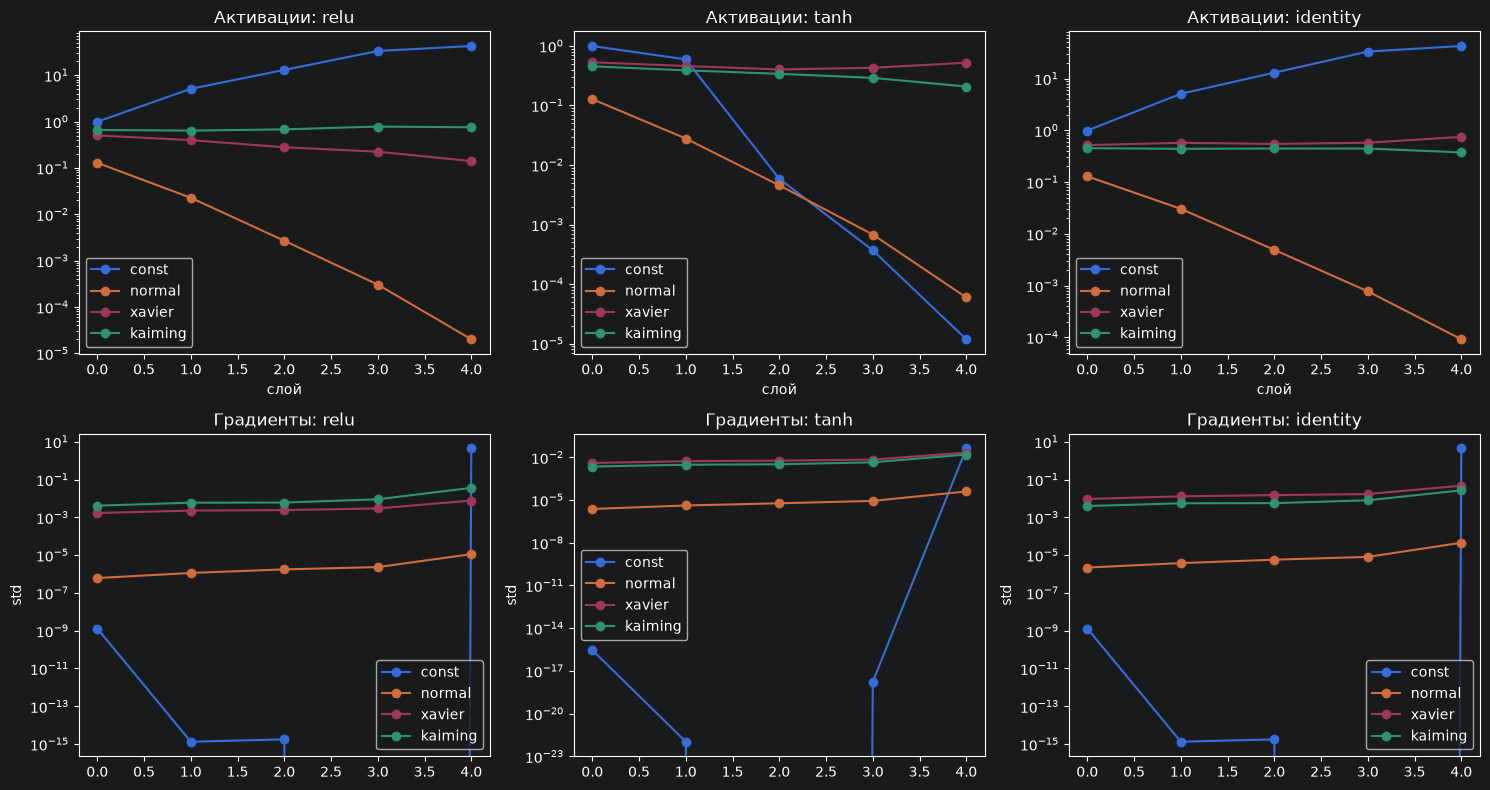

In [92]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, act_name in enumerate(act_fns):
    for init_type in inits:
        act_stats, grad_stats = results[(act_name, init_type)]
        act_std = [s['std'] for s in act_stats]
        grad_std = [s['std'] for s in grad_stats]
        axes[0, i].plot(act_std, label=init_type, marker='o')
        axes[1, i].plot(grad_std, label=init_type, marker='o')
    axes[0, i].set_title(f'Активации: {act_name}')
    axes[1, i].set_title(f'Градиенты: {act_name}')
    axes[0, i].set_yscale('log')   # важно!
    axes[1, i].set_yscale('log')
    axes[0, i].legend()
    axes[1, i].legend()
    axes[0, i].set_xlabel('слой')
    axes[1, i].set_ylabel('std')
plt.tight_layout()
plt.show()

## 2.Задание

In [93]:
class Node:
    def __init__(self, data, _children=(), _op=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op

    def __repr__(self):
        return f"Node(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Node) else Node(other)
        out = Node(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward
        return out

    def relu(self):
        out = Node(max(0.0, self.data), (self,), 'relu')

        def _backward():
            self.grad += (1.0 if out.data > 0 else 0.0) * out.grad

        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        self.grad = 1.0
        for v in reversed(topo):
            v._backward()


    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)

In [94]:
import unittest


class TestNode(unittest.TestCase):

    def test_add_forward(self):
        a = Node(2); b = Node(3)
        c = a + b
        self.assertEqual(c.data, 5)
        self.assertEqual(c._op, '+')

    def test_mul_forward(self):
        a = Node(2); b = Node(3)
        c = a * b
        self.assertEqual(c.data, 6)
        self.assertEqual(c._op, '*')

    def test_relu_forward(self):
        self.assertEqual(Node(5).relu().data, 5)
        self.assertEqual(Node(-5).relu().data, 0)
        self.assertEqual(Node(0).relu().data, 0)

    def test_add_backward(self):
        a = Node(2); b = Node(3)
        c = a + b
        c.backward()
        self.assertEqual(a.grad, 1)
        self.assertEqual(b.grad, 1)

    def test_mul_backward(self):
        a = Node(2); b = Node(3)
        c = a * b
        c.backward()
        self.assertEqual(a.grad, 3)
        self.assertEqual(b.grad, 2)

    def test_relu_backward_positive(self):
        a = Node(3)
        b = a.relu()
        b.backward()
        self.assertEqual(a.grad, 1)

    def test_relu_backward_negative(self):
        a = Node(-3)
        b = a.relu()
        b.backward()
        self.assertEqual(a.grad, 0)

    def test_chain_from_assignment(self):
        # a=2, b=-3, c=10
        # d = a + b*c = 2 - 30 = -28
        # e = relu(d) = 0
        a = Node(2); b = Node(-3); c = Node(10)
        d = a + b * c
        e = d.relu()
        e.backward()

        self.assertEqual(d.data, -28)
        self.assertEqual(e.data, 0)
        self.assertEqual(e.grad, 1)
        self.assertEqual(d.grad, 0)   # стандартный ReLU: производная при d<0 равна 0
        self.assertEqual(a.grad, 0)
        self.assertEqual(b.grad, 0)
        self.assertEqual(c.grad, 0)

    def test_chain_positive(self):
        # если d > 0 — градиенты текут
        a = Node(2); b = Node(3); c = Node(10)
        d = a + b * c       # = 32
        e = d.relu()        # = 32
        e.backward()

        self.assertEqual(d.grad, 1)
        self.assertEqual(a.grad, 1)
        self.assertEqual(b.grad, 10)   # ∂d/∂b = c
        self.assertEqual(c.grad, 3)    # ∂d/∂c = b

    def test_reuse_accumulates(self):
        a = Node(3)
        b = a + a
        b.backward()
        self.assertEqual(a.grad, 2)    # 1 + 1

    def test_reuse_mul(self):
        a = Node(3)
        b = a * a
        b.backward()
        self.assertEqual(a.grad, 6)    # a + a = 2a = 6

    def test_scalar_mul(self):
        a = Node(2)
        b = a * 3
        b.backward()
        self.assertEqual(b.data, 6)
        self.assertEqual(a.grad, 3)

    def test_scalar_add(self):
        a = Node(2)
        b = a + 5
        b.backward()
        self.assertEqual(b.data, 7)
        self.assertEqual(a.grad, 1)

    def test_sub(self):
        a = Node(5); b = Node(3)
        c = a - b
        c.backward()
        self.assertEqual(c.data, 2)
        self.assertEqual(a.grad, 1)
        self.assertEqual(b.grad, -1)


if __name__ == '__main__':
    unittest.main(argv=['first-arg-is-ignored'], exit=False, verbosity=2)

test_add_backward (__main__.TestNode.test_add_backward) ... ok
test_add_forward (__main__.TestNode.test_add_forward) ... ok
test_chain_from_assignment (__main__.TestNode.test_chain_from_assignment) ... ok
test_chain_positive (__main__.TestNode.test_chain_positive) ... ok
test_mul_backward (__main__.TestNode.test_mul_backward) ... ok
test_mul_forward (__main__.TestNode.test_mul_forward) ... ok
test_relu_backward_negative (__main__.TestNode.test_relu_backward_negative) ... ok
test_relu_backward_positive (__main__.TestNode.test_relu_backward_positive) ... ok
test_relu_forward (__main__.TestNode.test_relu_forward) ... ok
test_reuse_accumulates (__main__.TestNode.test_reuse_accumulates) ... ok
test_reuse_mul (__main__.TestNode.test_reuse_mul) ... ok
test_scalar_add (__main__.TestNode.test_scalar_add) ... ok
test_scalar_mul (__main__.TestNode.test_scalar_mul) ... ok
test_sub (__main__.TestNode.test_sub) ... ok
test_adam_bias_correction (__main__.TestOptimizers.test_adam_bias_correction) ... 

In [95]:
a = Node(2)
b = Node(-3)
c = Node(10)
d = a + b * c
e = d.relu()
e.backward()

print(a)
print(b)
print(c)
print(d)
print(e)

Node(data=2, grad=0.0)
Node(data=-3, grad=0.0)
Node(data=10, grad=0.0)
Node(data=-28, grad=0.0)
Node(data=0.0, grad=1.0)


## 3.Задание

In [96]:
import pandas as pd

In [97]:
class Adam:
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        self.params = list(params)
        self.lr = lr
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.m = [torch.zeros_like(p) for p in self.params]
        self.v = [torch.zeros_like(p) for p in self.params]
        self.t = 0

    @torch.no_grad()
    def step(self):
        self.t += 1
        for i, p in enumerate(self.params):
            if p.grad is None:
                continue
            g = p.grad
            self.m[i].mul_(self.beta1).add_(g, alpha=1 - self.beta1)
            self.v[i].mul_(self.beta2).addcmul_(g, g, value=1 - self.beta2)
            m_hat = self.m[i] / (1 - self.beta1 ** self.t)
            v_hat = self.v[i] / (1 - self.beta2 ** self.t)
            p.addcdiv_(m_hat, v_hat.sqrt().add_(self.eps), value=-self.lr)

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()


In [98]:
class SGDMomentum:
    def __init__(self, params, lr=1e-2, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.velocity = [torch.zeros_like(p) for p in self.params]

    @torch.no_grad()
    def step(self):
        for i, p in enumerate(self.params):
            if p.grad is None:
                continue
            v = self.velocity[i]
            v.mul_(self.momentum).add_(p.grad)
            p.add_(v, alpha=-self.lr)

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

In [99]:
class Nesterov:
    def __init__(self, params, lr=1e-2, momentum=0.9):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        self.velocity = [torch.zeros_like(p) for p in self.params]

    @torch.no_grad()
    def step(self):
        for i, p in enumerate(self.params):
            if p.grad is None:
                continue
            v = self.velocity[i]
            v.mul_(self.momentum).add_(p.grad)
            p.add_(p.grad + self.momentum * v, alpha=-self.lr)

    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()

In [100]:
class TestOptimizers(unittest.TestCase):

    def test_momentum_first_step(self):
        p = torch.nn.Parameter(torch.tensor([1.0, 2.0]))
        p.grad = torch.tensor([1.0, 1.0])
        opt = SGDMomentum([p], lr=0.1, momentum=0.9)
        opt.step()
        self.assertTrue(torch.allclose(p, torch.tensor([0.9, 1.9])))

    def test_momentum_accumulates(self):
        p = torch.nn.Parameter(torch.tensor([0.0]))
        opt = SGDMomentum([p], lr=0.1, momentum=0.9)
        p.grad = torch.tensor([1.0])
        opt.step()
        self.assertAlmostEqual(p.item(), -0.1, places=5)
        p.grad = torch.tensor([1.0])
        opt.step()
        self.assertAlmostEqual(p.item(), -0.29, places=5)

    def test_momentum_zero_grad(self):
        p = torch.nn.Parameter(torch.tensor([1.0]))
        p.grad = torch.tensor([1.0])
        opt = SGDMomentum([p], lr=0.1)
        opt.zero_grad()
        self.assertEqual(p.grad.item(), 0.0)

    def test_nesterov_first_step(self):
        p = torch.nn.Parameter(torch.tensor([1.0]))
        p.grad = torch.tensor([1.0])
        opt = Nesterov([p], lr=0.1, momentum=0.9)
        opt.step()
        self.assertAlmostEqual(p.item(), 0.81, places=5)

    def test_nesterov_differs_from_momentum(self):
        p1 = torch.nn.Parameter(torch.tensor([1.0]))
        p1.grad = torch.tensor([1.0])
        p2 = torch.nn.Parameter(torch.tensor([1.0]))
        p2.grad = torch.tensor([1.0])
        SGDMomentum([p1], lr=0.1, momentum=0.9).step()
        Nesterov([p2], lr=0.1, momentum=0.9).step()
        self.assertLess(p2.item(), p1.item())

    def test_adam_first_step(self):
        p = torch.nn.Parameter(torch.tensor([1.0]))
        p.grad = torch.tensor([1.0])
        opt = Adam([p], lr=0.1, betas=(0.9, 0.999), eps=1e-8)
        opt.step()
        self.assertAlmostEqual(p.item(), 0.9, places=5)

    def test_adam_zero_grad_no_change(self):
        p = torch.nn.Parameter(torch.tensor([1.0]))
        p.grad = torch.tensor([0.0])
        opt = Adam([p], lr=0.1)
        before = p.item()
        opt.step()
        self.assertAlmostEqual(p.item(), before, places=7)

    def test_adam_bias_correction(self):
        p = torch.nn.Parameter(torch.tensor([0.0]))
        p.grad = torch.tensor([0.1])
        opt = Adam([p], lr=0.1)
        opt.step()
        self.assertAlmostEqual(abs(p.item()), 0.1, places=3)

    def test_adam_zero_grad(self):
        p = torch.nn.Parameter(torch.tensor([1.0]))
        p.grad = torch.tensor([1.0])
        opt = Adam([p], lr=0.1)
        opt.zero_grad()
        self.assertEqual(p.grad.item(), 0.0)


unittest.main(argv=['first-arg-is-ignored'], exit=False, verbosity=2)

test_add_backward (__main__.TestNode.test_add_backward) ... ok
test_add_forward (__main__.TestNode.test_add_forward) ... ok
test_chain_from_assignment (__main__.TestNode.test_chain_from_assignment) ... ok
test_chain_positive (__main__.TestNode.test_chain_positive) ... ok
test_mul_backward (__main__.TestNode.test_mul_backward) ... ok
test_mul_forward (__main__.TestNode.test_mul_forward) ... ok
test_relu_backward_negative (__main__.TestNode.test_relu_backward_negative) ... ok
test_relu_backward_positive (__main__.TestNode.test_relu_backward_positive) ... ok
test_relu_forward (__main__.TestNode.test_relu_forward) ... ok
test_reuse_accumulates (__main__.TestNode.test_reuse_accumulates) ... ok
test_reuse_mul (__main__.TestNode.test_reuse_mul) ... ok
test_scalar_add (__main__.TestNode.test_scalar_add) ... ok
test_scalar_mul (__main__.TestNode.test_scalar_mul) ... ok
test_sub (__main__.TestNode.test_sub) ... ok
test_adam_bias_correction (__main__.TestOptimizers.test_adam_bias_correction) ... 

In [101]:
def compare_with_torch(opt_class, torch_class, our_kwargs=None, torch_kwargs=None):
    our_kwargs = our_kwargs or {}
    torch_kwargs = torch_kwargs or our_kwargs.copy()

    torch.manual_seed(0)
    p1 = torch.nn.Parameter(torch.randn(5))
    p1_clone = p1.detach().clone()
    p2 = torch.nn.Parameter(p1_clone.clone())

    opt1 = opt_class([p1], **our_kwargs)
    opt2 = torch_class([p2], **torch_kwargs)

    for _ in range(10):
        grad = torch.randn(5)
        p1.grad = grad.clone()
        p2.grad = grad.clone()
        opt1.step()
        opt2.step()
        opt1.zero_grad()
        opt2.zero_grad()

    print(f"{opt_class.__name__}: max diff = {(p1 - p2).abs().max().item():.2e}")

compare_with_torch(
    SGDMomentum, torch.optim.SGD,
    our_kwargs={'lr': 0.1, 'momentum': 0.9},
    torch_kwargs={'lr': 0.1, 'momentum': 0.9},
)

compare_with_torch(
    Nesterov, torch.optim.SGD,
    our_kwargs={'lr': 0.1, 'momentum': 0.9},
    torch_kwargs={'lr': 0.1, 'momentum': 0.9, 'nesterov': True},
)

compare_with_torch(
    Adam, torch.optim.Adam,
    our_kwargs={'lr': 0.1},
    torch_kwargs={'lr': 0.1},
)

SGDMomentum: max diff = 0.00e+00
Nesterov: max diff = 0.00e+00
Adam: max diff = 8.94e-08


In [102]:
def train_with_optimizer(optimizer_class, opt_name, act_fn=None,
                         epochs=5, lr=1e-2, **opt_kwargs):
    if act_fn is None:
        act_fn = torch.nn.ReLU()

    torch.manual_seed(42)
    model = BaseNetwork(act_fn=act_fn).to(device)

    def init_weights(m):
        if isinstance(m, torch.nn.Linear):
            torch.nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            torch.nn.init.zeros_(m.bias)
    model.apply(init_weights)

    optimizer = optimizer_class(model.parameters(), lr=lr, **opt_kwargs)
    loss_fn = torch.nn.CrossEntropyLoss()

    history = {
        'train_loss': [], 'val_loss': [], 'val_acc': [],
        'grad_norm': [], 'weight_std': [],
    }

    for epoch in range(epochs):
        model.train()
        running = 0.0
        grad_norms = []

        for xb, yb in train_dataloader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()

            total_norm = 0.0
            for p in model.parameters():
                if p.grad is not None:
                    total_norm += p.grad.norm().item() ** 2
            grad_norms.append(total_norm ** 0.5)

            optimizer.step()
            running += loss.item()

        history['train_loss'].append(running / len(train_dataloader))
        history['grad_norm'].append(sum(grad_norms) / len(grad_norms))

        w_std = torch.cat([p.flatten() for p in model.parameters()]).std().item()
        history['weight_std'].append(w_std)

        model.eval()
        running, correct = 0.0, 0
        with torch.no_grad():
            for xb, yb in test_dataloader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                running += loss_fn(out, yb).item()
                correct += (out.argmax(1) == yb).sum().item()
        history['val_loss'].append(running / len(test_dataloader))
        history['val_acc'].append(correct / len(test_data))

        print(f"[{opt_name}] epoch {epoch+1}: "
              f"train={history['train_loss'][-1]:.4f} "
              f"val={history['val_loss'][-1]:.4f} "
              f"acc={history['val_acc'][-1]:.4f} "
              f"|g|={history['grad_norm'][-1]:.4f} "
              f"sigma_w={history['weight_std'][-1]:.4f}")

    return history

[Momentum] epoch 1: train=0.5151 val=0.4565 acc=0.8306 |g|=2.2988 sigma_w=0.0612
[Momentum] epoch 2: train=0.3694 val=0.3871 acc=0.8583 |g|=1.8195 sigma_w=0.0616
[Momentum] epoch 3: train=0.3313 val=0.3689 acc=0.8657 |g|=1.7276 sigma_w=0.0620
[Momentum] epoch 4: train=0.3052 val=0.3563 acc=0.8695 |g|=1.6783 sigma_w=0.0623
[Momentum] epoch 5: train=0.2853 val=0.3669 acc=0.8644 |g|=1.6617 sigma_w=0.0627
[Nesterov] epoch 1: train=0.4900 val=0.4814 acc=0.8264 |g|=2.4773 sigma_w=0.0612
[Nesterov] epoch 2: train=0.3576 val=0.3829 acc=0.8593 |g|=1.9651 sigma_w=0.0616
[Nesterov] epoch 3: train=0.3226 val=0.3846 acc=0.8591 |g|=1.8619 sigma_w=0.0619
[Nesterov] epoch 4: train=0.2996 val=0.3494 acc=0.8674 |g|=1.8198 sigma_w=0.0623
[Nesterov] epoch 5: train=0.2805 val=0.3485 acc=0.8702 |g|=1.8055 sigma_w=0.0626
[Adam] epoch 1: train=0.4782 val=0.4655 acc=0.8258 |g|=2.0931 sigma_w=0.0650
[Adam] epoch 2: train=0.3621 val=0.3767 acc=0.8634 |g|=1.3961 sigma_w=0.0687
[Adam] epoch 3: train=0.3278 val=0.3

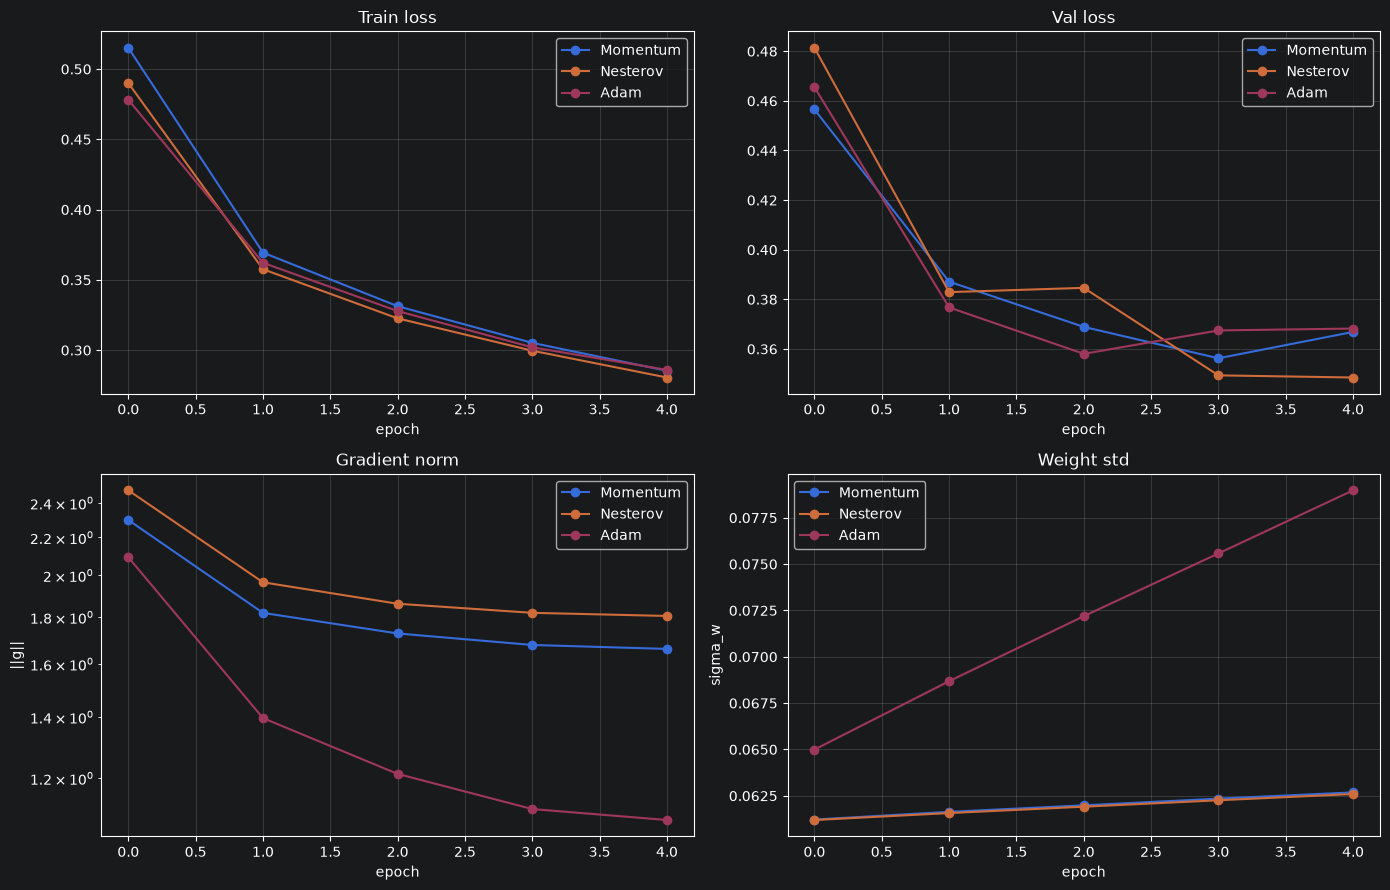

optimizer  final_train_loss  final_val_loss  best_val_loss  final_val_acc  final_grad_norm  final_weight_std
 Nesterov          0.280529        0.348507       0.348507         0.8702         1.805493          0.062595
 Momentum          0.285290        0.366875       0.356262         0.8644         1.661722          0.062683
     Adam          0.285952        0.368239       0.358052         0.8642         1.080119          0.078981


In [103]:
histories = {}

histories['Momentum'] = train_with_optimizer(
    SGDMomentum, 'Momentum', lr=1e-2, momentum=0.9, epochs=5
)

histories['Nesterov'] = train_with_optimizer(
    Nesterov, 'Nesterov', lr=1e-2, momentum=0.9, epochs=5
)

histories['Adam'] = train_with_optimizer(
    Adam, 'Adam', lr=1e-3, betas=(0.9, 0.999), eps=1e-8, epochs=5
)


fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for name, h in histories.items():
    axes[0, 0].plot(h['train_loss'], label=name, marker='o')
axes[0, 0].set_title('Train loss')
axes[0, 0].set_xlabel('epoch')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

for name, h in histories.items():
    axes[0, 1].plot(h['val_loss'], label=name, marker='o')
axes[0, 1].set_title('Val loss')
axes[0, 1].set_xlabel('epoch')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

for name, h in histories.items():
    axes[1, 0].plot(h['grad_norm'], label=name, marker='o')
axes[1, 0].set_title('Gradient norm')
axes[1, 0].set_xlabel('epoch')
axes[1, 0].set_ylabel('||g||')
axes[1, 0].set_yscale('log')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

for name, h in histories.items():
    axes[1, 1].plot(h['weight_std'], label=name, marker='o')
axes[1, 1].set_title('Weight std')
axes[1, 1].set_xlabel('epoch')
axes[1, 1].set_ylabel('sigma_w')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


rows = []
for name, h in histories.items():
    rows.append({
        'optimizer': name,
        'final_train_loss': h['train_loss'][-1],
        'final_val_loss':   h['val_loss'][-1],
        'best_val_loss':    min(h['val_loss']),
        'final_val_acc':    h['val_acc'][-1],
        'final_grad_norm':  h['grad_norm'][-1],
        'final_weight_std': h['weight_std'][-1],
    })

df = pd.DataFrame(rows).sort_values('final_val_loss')
print(df.to_string(index=False))